# Notebook 03 — Model Evaluation and Selection

**Project:** AI-Readiness Investment Intelligence for Africa

## 1. Objective

Evaluate the clustering experiments conducted in Notebook 02,
select and justify a defensible final clustering configuration,
and generate reproducible cluster assignments for 2,172 African
urban centres.

The evaluation considers internal clustering quality, initialization
stability, preprocessing sensitivity, cluster-size distributions
and substantive interpretability.

The resulting clusters represent empirical infrastructure profiles,
not independently verified AI-readiness levels or investment suitability.

## PART 1: Data and Experimental Setup

### Load the analytical dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load the prepared analytical dataset from Notebook 01
data_path = PROJECT_ROOT / "data" / "processed" / "africa_ai_readiness_analytical.csv"

df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape}")
print(f"Urban centres: {len(df):,}")
print(f"Columns: {df.columns.tolist()}")
print(f"Missing values: {df.isna().sum().sum():,}")

Dataset shape: (2172, 16)
Urban centres: 2,172
Columns: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distance_band_km', 'IN_CIS_TRA_2020', 'IN_ROA_DEN_2024', 'SC_SEC_SYT_2020', 'IN_CIS_EDU_2020', 'IN_CIS_WAT_2020', 'CL_REN_PVO_2020', 'CL_B01_CUR_2010', 'peeringdb_facility_count']
Missing values: 0


### Clustering predictors and preprocessing

In [2]:
# Inspect the analytical dataset structure
print("Dataset columns and data types:")
print(df.dtypes.to_string())

print("\nFirst 10 observations:")
display(df.head(10))

Dataset columns and data types:
ID_UC_G0                      int64
GC_UCN_MAI_2025                 str
GC_CNT_GAD_2025                 str
GH_POP_TOT_2025             float64
SC_GDP_AVG_2020             float64
IN_CIS_ENE_2020             float64
IN_CIS_TEL_2020             float64
fibre_distance_band_km        int64
IN_CIS_TRA_2020             float64
IN_ROA_DEN_2024             float64
SC_SEC_SYT_2020             float64
IN_CIS_EDU_2020             float64
IN_CIS_WAT_2020             float64
CL_REN_PVO_2020             float64
CL_B01_CUR_2010             float64
peeringdb_facility_count      int64

First 10 observations:


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count
0,38,Mindelo,Cabo Verde,8.827388e+04,2.466210e+07,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0
1,39,Dakar,Senegal,3.970202e+06,6.282993e+07,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2
2,40,Serrekunda,Gambia,1.313465e+06,1.359119e+07,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0
3,41,Nouadhibou,Mauritania,1.774690e+05,2.835348e+07,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0
4,43,Bissau,Guinea-Bissau,6.744443e+05,1.800221e+07,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0
5,46,Kamsar,Guinea,1.279576e+05,5.522906e+06,0.000000e+00,1.061160e-04,50,0.002419,0.006819,1.943000,0.000555,0.000000e+00,4.364,26.434,0
6,47,Freetown,Sierra Leone,2.150533e+06,2.445415e+07,3.035146e-03,2.400143e-03,10,0.005904,0.008462,7.974652,0.001853,3.490000e-06,4.038,26.029,2
7,49,Kayes,Mali,2.873910e+05,7.857937e+06,1.270654e-03,8.809970e-04,5,0.009818,0.015712,1.582000,0.001954,9.570000e-05,4.584,30.403,0
8,50,Monrovia,Liberia,2.049818e+06,1.152906e+07,2.141840e-04,2.033260e-04,5,0.006480,0.007292,6.911517,0.000683,7.120000e-05,3.851,26.202,0
9,52,Danané,CÃ´te d'Ivoire,1.011363e+05,2.102356e+07,8.320908e-03,0.000000e+00,5,0.003097,0.009461,3.536000,0.000540,0.000000e+00,4.001,25.680,0


### Reproduce the baseline preprocessing configuration

To ensure consistency and reproducibility, this section reconstructs the baseline preprocessing pipeline established in Notebook 02. The analysis uses 12 numerical predictors for 2,172 African urban centres, excluding identification fields and PeeringDB facility counts. Population and GDP undergo base-10 logarithmic transformation, while five GHSL infrastructure indices receive zero-preserving logarithmic transformations. StandardScaler is then applied to obtain the feature matrix used for the initial clustering experiments. RobustScaler remains an alternative for sensitivity assessment. This ensures that model evaluation builds on the same analytical configuration rather than introducing new preprocessing assumptions.

In [3]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# Reconstruct the 12-predictor baseline from Notebook 02
id_columns = [
    "ID_UC_G0",
    "GC_UCN_MAI_2025",
    "GC_CNT_GAD_2025",
]

X_baseline = df.drop(
    columns=id_columns + ["peeringdb_facility_count"]
).copy()

# Apply base-10 logarithmic transformations
log_features = ["GH_POP_TOT_2025", "SC_GDP_AVG_2020"]

X_prepared = X_baseline.copy()

for col in log_features:
    X_prepared[col] = np.log10(X_prepared[col])

# Apply zero-preserving transformations to GHSL infrastructure indices
infrastructure_features = [
    "IN_CIS_ENE_2020",
    "IN_CIS_TEL_2020",
    "IN_CIS_TRA_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_WAT_2020",
]

for col in infrastructure_features:
    positive_median = X_baseline.loc[
        X_baseline[col] > 0, col
    ].median()

    X_prepared[col] = np.log1p(
        X_baseline[col] / positive_median
    )

# Reproduce StandardScaler preprocessing
standard_scaler = StandardScaler()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_prepared),
    columns=X_prepared.columns,
    index=X_prepared.index,
)

# Verify the resulting feature matrix
print("Baseline shape:", X_baseline.shape)
print("Prepared shape:", X_prepared.shape)
print("Scaled shape:", X_standard.shape)
print("Missing values:", X_standard.isna().sum().sum())
print("All values finite:", np.isfinite(X_standard.to_numpy()).all())

display(X_standard.head())


Baseline shape: (2172, 12)
Prepared shape: (2172, 12)
Scaled shape: (2172, 12)
Missing values: 0
All values finite: True


,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
0,-0.432271,0.563253,-0.906500,-0.654309,-0.387008,-0.905266,0.790976,0.219274,-0.076258,-0.363830,-0.374702,-0.185807
1,3.707082,1.711104,0.860915,1.698992,-0.533247,2.678049,2.456753,-0.355349,3.153209,1.550212,0.559386,0.172266
2,2.504091,-0.168108,-0.838912,1.714343,-0.679486,0.832137,1.012828,-0.107728,1.395847,0.725197,0.392585,0.348724
3,0.327221,0.734458,-0.903956,0.677042,-0.679486,-0.015590,0.415833,1.055339,-0.643290,-0.257167,1.346690,-0.949681
4,1.779201,0.176890,-0.906504,-0.644609,-0.679486,-0.076385,-0.278083,0.295839,-0.093363,-0.364020,0.052310,0.722792


## Comparative Evaluation of Candidate Clustering Models

This section compares K-Means and Ward-linkage Agglomerative
Hierarchical Clustering using the verified 12-feature StandardScaler
matrix for 2,172 African urban centres.

Based on the exploratory experiments in Notebook 02, three candidate
cluster configurations (k = 2, 3 and 6) are retained for comparative
evaluation.

Model performance is assessed using the Silhouette Score (higher is
better), Davies–Bouldin Index (lower is better), and minimum cluster
size. The Adjusted Rand Index (ARI) measures agreement between
the two algorithms.

The objective is to identify a defensible clustering configuration
for subsequent robustness assessment and interpretation of urban
infrastructure-readiness profiles. Internal clustering metrics
are not treated as evidence of investment suitability.

In [4]:

import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

# Candidate configurations shortlisted in Notebook 02
candidate_k = [2, 3, 6]
comparison_results = []
candidate_labels = {}

for k in candidate_k:
    # K-Means reference configuration
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    km_labels = kmeans.fit_predict(X_standard)

    # Ward-linkage Agglomerative Clustering
    agglomerative = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    agg_labels = agglomerative.fit_predict(X_standard)

    candidate_labels[("K-Means", k)] = km_labels
    candidate_labels[("Agglomerative", k)] = agg_labels

    # Agreement between algorithms at the same k
    ari = adjusted_rand_score(km_labels, agg_labels)

    for algorithm, labels in [
        ("K-Means", km_labels),
        ("Agglomerative", agg_labels)
    ]:
        comparison_results.append({
            "k": k,
            "Algorithm": algorithm,
            "Silhouette": silhouette_score(
                X_standard, labels
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_standard, labels
            ),
            "Smallest_Cluster": pd.Series(
                labels
            ).value_counts().min(),
            "ARI_vs_Other": ari
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


,k,Algorithm,Silhouette,Davies_Bouldin,Smallest_Cluster,ARI_vs_Other
0,2,K-Means,0.2496,1.7050,747,0.6780
1,2,Agglomerative,0.2433,1.7247,627,0.6780
2,3,K-Means,0.2065,1.7994,270,0.4171
3,3,Agglomerative,0.1337,1.8514,376,0.4171
4,6,K-Means,0.1840,1.6430,69,0.6150
5,6,Agglomerative,0.1450,2.0540,218,0.6150


### Interpretation of Comparative Clustering Results

The comparative evaluation reproduced the preliminary findings from Notebook 02. K-Means consistently outperformed Ward-linkage Agglomerative Clustering across the three shortlisted configurations (k = 2, 3 and 6), achieving higher Silhouette Scores and lower Davies–Bouldin Indices under the same StandardScaler preprocessing configuration.

The k = 2 K-Means solution achieved the highest Silhouette Score (0.2496), while k = 6 achieved the lowest Davies–Bouldin Index (1.6430). The k = 3 solution offers an intermediate level of differentiation, although its suitability requires further assessment.

Agreement between the algorithms was partial, with Adjusted Rand Index values ranging from 0.4171 to 0.6780, indicating that cluster assignments depend on the clustering method.

Overall, the results support retaining K-Means as the preferred algorithm for further evaluation. Final selection of the number of clusters will consider robustness, cluster distributions and substantive interpretability rather than internal evaluation metrics alone.

In [5]:

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Use the standardized feature matrix from Notebook 01
X = np.asarray(X_standard)

candidate_k = [2, 3, 6]
n_repeats = 20
sample_fraction = 0.80

rng = np.random.default_rng(42)
sample_size = int(len(X) * sample_fraction)

stability_results = []

for k in candidate_k:
    all_labels = []

    for repeat in range(n_repeats):
        # Randomly select 80% of urban centres
        sample_idx = rng.choice(
            len(X),
            size=sample_size,
            replace=False
        )

        # Fit K-Means on the subsample
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        )
        model.fit(X[sample_idx])

        # Assign all urban centres using fitted centroids
        labels = model.predict(X)
        all_labels.append(labels)

    # Compare every pair of resampling runs
    ari_scores = [
        adjusted_rand_score(all_labels[i], all_labels[j])
        for i in range(n_repeats)
        for j in range(i + 1, n_repeats)
    ]

    stability_results.append({
        "k": k,
        "Mean ARI": np.mean(ari_scores),
        "Std ARI": np.std(ari_scores),
        "Minimum ARI": np.min(ari_scores),
        "Maximum ARI": np.max(ari_scores)
    })

resampling_stability_df = pd.DataFrame(stability_results)

display(resampling_stability_df.round(4))


,k,Mean ARI,Std ARI,Minimum ARI,Maximum ARI
0,2,0.9775,0.0085,0.9558,0.9981
1,3,0.8688,0.1976,0.4417,0.9941
2,6,0.8432,0.1336,0.6614,0.9833


### Evaluate additional K-Means configurations

Focused sensitivity extension for k = 11–20

In [6]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np
import pandas as pd

# Same standardized feature space as previous experiments
X = np.asarray(X_standard)

extended_results = []

for k in range(11, 21):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X)
    cluster_sizes = np.bincount(labels, minlength=k)

    extended_results.append({
        "k": k,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Inertia": model.inertia_,
        "Smallest cluster": cluster_sizes.min(),
        "Largest cluster": cluster_sizes.max()
    })

extended_k_df = pd.DataFrame(extended_results)

display(extended_k_df.round(4))


,k,Silhouette,Davies-Bouldin,Inertia,Smallest cluster,Largest cluster
0,11,0.1574,1.7124,11213.1968,50,309
1,12,0.1642,1.7142,10919.7453,51,322
2,13,0.1595,1.6912,10607.0923,52,288
3,14,0.1610,1.7443,10358.0854,48,278
4,15,0.1533,1.6883,10145.1767,38,233
5,16,0.1537,1.7259,9882.7620,47,218
6,17,0.1606,1.6906,9667.9915,51,247
7,18,0.1592,1.7118,9486.8947,38,238
8,19,0.1612,1.6951,9305.6878,32,245
9,20,0.1502,1.7242,9220.7134,32,190


### Candidate Cluster Range and Sensitivity Assessment

The initial candidate range of k = 2–10 was selected to explore a manageable number of interpretable urban infrastructure profiles suitable for continental-scale investment screening. Following established cluster-validation approaches (Rousseeuw, 1987; Milligan & Cooper, 1985), candidate solutions were assessed using multiple internal validation metrics rather than assuming a predefined optimal number of clusters.

To examine the sensitivity of model selection to the initial search range, the analysis was extended to k = 11–20. None of the additional configurations improved upon the best Silhouette Score (0.2496, k = 2) or Davies–Bouldin Index (1.6430, k = 6) obtained from the original candidates. The extension therefore provided no evidence that increasing the number of clusters beyond ten would improve these evaluation criteria within the tested range.

Final model selection considers statistical performance, stability, cluster sizes and the interpretability of infrastructure profiles in relation to the project's investment-screening objectives.

# PART 2: Cluster profiling for k = 2, 3 and 6

### Cluster Profiling and Interpretability Assessment

In [7]:

# Cluster profiles for shortlisted K-Means configurations
from sklearn.cluster import KMeans
import pandas as pd

candidate_k = [2, 3, 6]

# Preserve predictor names from the standardized dataset
X_profile = X_standard.copy()

cluster_profiles = {}
cluster_sizes = {}
cluster_assignments = {}

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_profile)

    # Store cluster membership for later analysis
    cluster_assignments[k] = labels

    # Calculate mean standardized feature values per cluster
    profile_df = X_profile.copy()
    profile_df["Cluster"] = labels

    cluster_profiles[k] = (
        profile_df.groupby("Cluster")
        .mean()
        .round(3)
    )

    cluster_sizes[k] = (
        profile_df["Cluster"]
        .value_counts()
        .sort_index()
    )

    print(f"\n{'='*55}")
    print(f"K-MEANS CLUSTER PROFILES: k = {k}")
    print(f"{'='*55}")

    print("\nCluster sizes:")
    display(cluster_sizes[k].to_frame("Urban centres"))

    print("\nMean standardized feature values:")
    display(cluster_profiles[k])



K-MEANS CLUSTER PROFILES: k = 2

Cluster sizes:


,Urban centres
Cluster,
0,1425
1,747



Mean standardized feature values:


,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
Cluster,,,,,,,,,,,,
0,-0.244,-0.398,-0.533,-0.274,0.150,-0.529,-0.356,-0.353,-0.370,-0.198,-0.226,0.324
1,0.465,0.759,1.017,0.523,-0.285,1.009,0.679,0.673,0.706,0.377,0.432,-0.619



K-MEANS CLUSTER PROFILES: k = 3

Cluster sizes:


,Urban centres
Cluster,
0,522
1,1380
2,270


... (2 outputs left out)


K-MEANS CLUSTER PROFILES: k = 6

Cluster sizes:


,Urban centres
Cluster,
0,421
1,349
2,714
3,215
4,404
5,69



Mean standardized feature values:


,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
Cluster,,,,,,,,,,,,
0,-0.087,0.967,1.186,-0.181,-0.068,0.825,0.669,0.749,0.057,-0.163,0.854,-0.739
1,-0.371,-0.500,-0.736,-0.444,1.831,-0.883,-0.691,-0.560,-0.630,-0.308,0.092,0.241
2,-0.199,-0.573,-0.444,-0.106,-0.518,-0.453,0.008,-0.824,-0.256,-0.252,0.241,0.174
3,1.339,0.771,1.100,2.012,-0.528,1.561,0.805,0.729,1.914,1.069,0.022,-0.662
4,0.065,0.043,-0.381,-0.342,-0.267,-0.124,-0.586,0.790,-0.111,-0.313,-1.463,0.622
5,-0.089,-0.100,-0.114,0.184,-0.279,-0.024,0.260,-0.111,0.176,3.663,0.332,-0.088


### Visual comparison using heatmaps

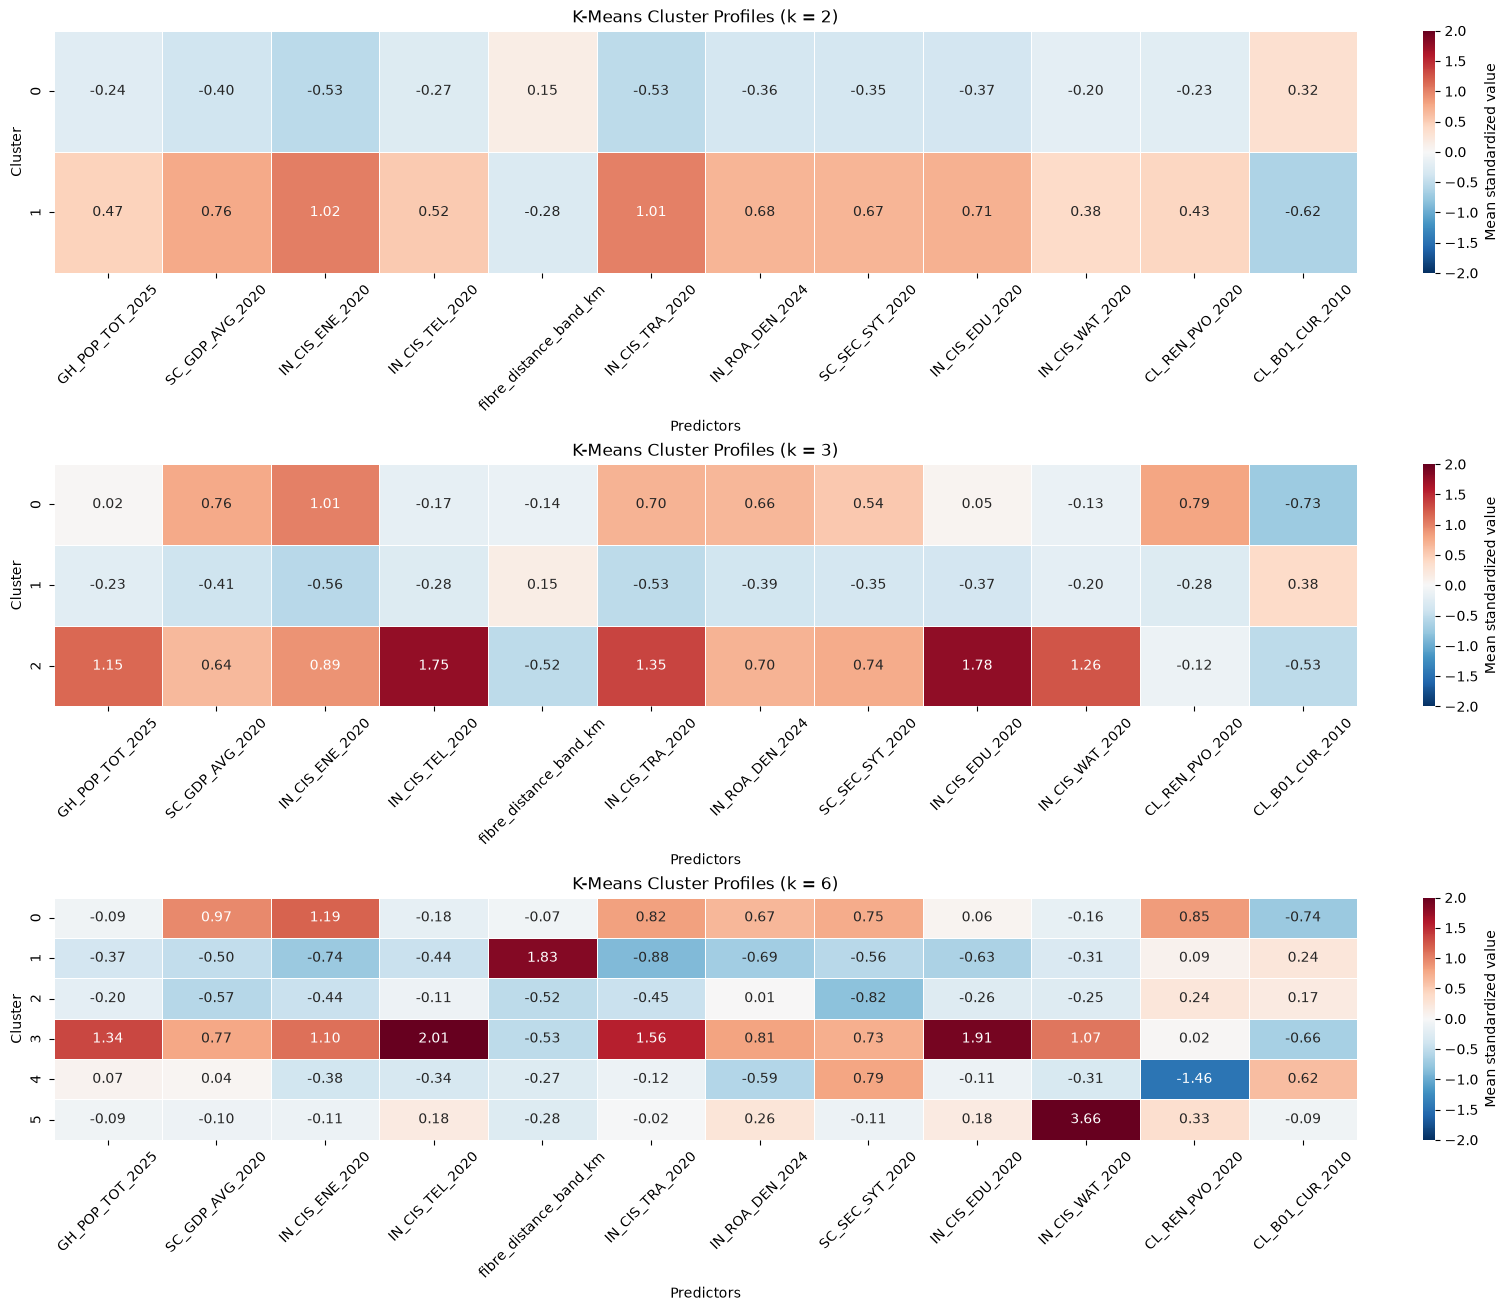

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 13),
    constrained_layout=True
)

for ax, k in zip(axes, [2, 3, 6]):
    sns.heatmap(
        cluster_profiles[k],
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-2,
        vmax=2,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Mean standardized value"}
    )

    ax.set_title(f"K-Means Cluster Profiles (k = {k})")
    ax.set_xlabel("Predictors")
    ax.set_ylabel("Cluster")

    ax.tick_params(axis="x", rotation=45)

plt.show()


## k = 3 assignment stability

In [9]:

from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd

X = np.asarray(X_standard)
k = 3
n_repeats = 20
rng = np.random.default_rng(42)

# Full-data reference model
reference = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=20,
    random_state=42
).fit(X)

reference_labels = reference.labels_
aligned_runs = []
run_ari = []

for repeat in range(n_repeats):
    idx = rng.choice(
        len(X),
        size=int(0.8 * len(X)),
        replace=False
    )

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    ).fit(X[idx])

    predicted = model.predict(X)

    # Align cluster labels to the reference
    overlap = np.zeros((k, k), dtype=int)

    for a in range(k):
        for b in range(k):
            overlap[a, b] = np.sum(
                (reference_labels == a) &
                (predicted == b)
            )

    rows, cols = linear_sum_assignment(-overlap)
    mapping = dict(zip(cols, rows))
    aligned = np.array([mapping[v] for v in predicted])

    aligned_runs.append(aligned)
    run_ari.append(
        adjusted_rand_score(reference_labels, predicted)
    )

aligned_runs = np.array(aligned_runs)

# Fraction of runs disagreeing with reference
change_rate = (
    aligned_runs != reference_labels
).mean(axis=0)

# Relative distance margin to competing centroid
distances = reference.transform(X)
sorted_distances = np.sort(distances, axis=1)

margin = (
    (sorted_distances[:, 1] - sorted_distances[:, 0]) /
    (sorted_distances[:, 1] + 1e-12)
)

diagnostic_df = pd.DataFrame({
    "Reference cluster": reference_labels,
    "Change rate": change_rate,
    "Distance margin": margin
})

print("ARI against full-data reference:")
print(pd.Series(run_ari).describe().round(4))

print("\nAssignment stability by reference cluster:")
display(
    diagnostic_df.groupby("Reference cluster").agg(
        Urban_centres=("Change rate", "size"),
        Mean_change_rate=("Change rate", "mean"),
        Unstable_share=(
            "Change rate",
            lambda x: (x > 0.2).mean()
        ),
        Mean_distance_margin=("Distance margin", "mean")
    ).round(4)
)

print("\nCorrelation between change rate and margin:")
print(
    diagnostic_df[
        ["Change rate", "Distance margin"]
    ].corr().round(4)
)


ARI against full-data reference:
count    20.0000
mean      0.8697
std       0.2055
min       0.4664
25%       0.9609
50%       0.9668
75%       0.9736
max       0.9810
dtype: float64

Assignment stability by reference cluster:


,Urban_centres,Mean_change_rate,Unstable_share,Mean_distance_margin
Reference cluster,,,,
0,522,0.0537,0.0613,0.2929
1,1380,0.0597,0.0101,0.3539
2,270,0.1919,0.0741,0.2369



Correlation between change rate and margin:
                 Change rate  Distance margin
Change rate           1.0000          -0.3407
Distance margin      -0.3407           1.0000



### Part 2 Summary: Cluster Profiling and Assignment Stability

**Objective:** Examine the interpretability of the shortlisted K-Means configurations (k = 2, 3 and 6), compare their infrastructure profiles, and assess the assignment stability of the three-cluster solution.

#### 1. Cluster profiling

Cluster profiles were calculated as the mean standardized predictor values for urban centres assigned to each cluster. Heatmaps were used to compare the relative characteristics of the resulting groups across the 12 predictors.

- **k = 2:** Produces two broad groups of 1,425 and 747 urban centres, primarily differentiated by socioeconomic characteristics and infrastructure indicators. This solution provides a relatively simple distinction but conceals potentially important variation within groups.
- **k = 3:** Produces groups of 522, 1,380 and 270 urban centres. The heatmap indicates more differentiated infrastructure and socioeconomic profiles, including a smaller group with comparatively elevated values across several infrastructure indicators.
- **k = 6:** Reveals more specialized profiles, including groups distinguished by telecommunications, education and water infrastructure. However, the additional granularity introduces smaller groups (the smallest contains 69 urban centres) and greater interpretive complexity.

All heatmap values represent **cluster means in standardized feature space (z-scores)**. Positive values indicate above-average values for the corresponding predictor across the analytical dataset, while negative values indicate below-average values. They do not necessarily indicate favourable or unfavourable investment conditions.

#### 2. Assignment stability for k = 3

The three-cluster solution was examined using 20 subsampling repetitions, comparing cluster assignments with the full-data reference solution after label alignment.

**Adjusted Rand Index (ARI):**
- Mean: 0.8697
- Median: 0.9668
- Minimum: 0.4664
- Maximum: 0.9810

The high median indicates that most subsampling runs reproduce assignments closely resembling the full-data reference. However, the substantially lower minimum and the standard deviation of 0.2055 indicate that some runs produce materially different assignments.

**Assignment changes by reference cluster:**

| Cluster | Urban centres | Mean change rate | Unstable share (>20% of runs) |
|---|---:|---:|---:|
| 0 | 522 | 5.37% | 6.13% |
| 1 | 1,380 | 5.97% | 1.01% |
| 2 | 270 | 19.19% | 7.41% |

Cluster 2 exhibits the highest average assignment-change rate, suggesting that its membership is more sensitive to subsampling than that of the other groups.

The correlation between assignment-change rate and centroid-distance margin is **−0.3407**. This indicates that urban centres closer to competing centroids tend to change assignments more frequently, although the relationship is moderate and does not fully explain the observed instability.

#### 3. Interpretation and limitations

The results suggest that k = 3 provides potentially useful exploratory differentiation beyond the broad k = 2 partition, but its stability is not uniform across clusters.

The assignment-stability analysis provides evidence that boundary ambiguity contributes to changes in cluster membership. Nevertheless, the lower-ARI runs cannot be assumed to reflect only boundary effects, and the analysis does not independently establish that all cluster profiles remain substantively unchanged.

Cluster membership should therefore be interpreted as an exploratory description of multidimensional urban characteristics, **not as independently validated AI-readiness categories or investment rankings**.

#### 4. Next steps

Before finalizing the model-selection decision and assigning substantive cluster names:

1. Verify the definitions, units, source years and transformations of the 12 predictors.
2. Confirm the interpretation and direction of each indicator, especially fibre distance, sectoral infrastructure indices and solar PV potential.
3. Replace technical predictor codes in the visualizations with descriptive labels.
4. Document the final clustering choice and its limitations, then preserve the selected cluster assignments for subsequent geographical and investment-screening analyses.

**Status:** Cluster profiling and the targeted k = 3 assignment-stability diagnostic are complete. Final interpretation and model selection remain pending predictor verification.


## PART 3: Predictor Selection, Definitions and Data Sources



### 3.1 Predictor dictionary

The clustering analysis uses 12 predictors describing demographic, socioeconomic, infrastructure, connectivity and environmental characteristics of 2,172 African urban centres.

Eleven predictors originate from the GHSL Urban Centre Database (R2024A). The terrestrial fibre-proximity variable was integrated separately from ITU data.

The following table documents the indicators and their preprocessing transformations.

| Predictor code | Descriptive name | Definition / measurement | Reference year | Preprocessing |
|---|---|---|---|---|
| GH_POP_TOT_2025 | Urban population | Total population within the urban centre | 2025 | log10(x) |
| SC_GDP_AVG_2020 | Average GDP (PPP) | Average gridded GDP value within the urban centre | 2020 | log10(x) |
| IN_CIS_ENE_2020 | Energy infrastructure | CISI energy-sector infrastructure indicator | 2020 | log1p(x/m) |
| IN_CIS_TEL_2020 | Telecom infrastructure | CISI telecommunications infrastructure indicator | 2020 | log1p(x/m) |
| fibre_distance_band_km | Fibre proximity (distance band) | Encoded terrestrial fibre-proximity category; not an observed continuous distance | ITU source vintage to verify | None |
| IN_CIS_TRA_2020 | Transport infrastructure | CISI transport-sector infrastructure indicator | 2020 | log1p(x/m) |
| IN_ROA_DEN_2024 | Road network density | GHSL road-network density indicator | 2024 | None |
| SC_SEC_SYT_2020 | Mean years of schooling | Average years of schooling for adults aged 25+ | 2020 | None |
| IN_CIS_EDU_2020 | Education infrastructure | CISI education-sector infrastructure indicator | 2020 | log1p(x/m) |
| IN_CIS_WAT_2020 | Water infrastructure | CISI water-sector infrastructure indicator | 2020 | log1p(x/m) |
| CL_REN_PVO_2020 | Solar PV potential | Average daily photovoltaic electricity-generation potential (kWh/kWp) | 2020 | None |
| CL_B01_CUR_2010 | Mean annual temperature | Annual mean temperature indicator | 2010 | None |

**Sources:** GHSL Urban Centre Database R2024A technical documentation and indicator fact sheets; ITU terrestrial fibre-proximity data; project data-preparation and clustering notebooks.

**Preprocessing notes:**

- `log10(x)` was applied to population and GDP.
- `log1p(x/m)` was applied to the five infrastructure indices, where `m` is the median of strictly positive observations for the corresponding indicator.
- The other five predictors were retained without additional variable-specific transformation.
- All 12 prepared predictors were subsequently standardized using `StandardScaler` for the reference clustering experiments.
- The fibre variable uses encoded distance-band approximations, including a provisional value of 125 km for the category greater than 100 km.
- CISI indicators represent mapped infrastructure characteristics, not verified service reliability or quality.
- Solar PV potential represents resource potential, not installed renewable-energy capacity.
- Mean years of schooling is a general educational-attainment indicator, not a direct measure of AI-specific skills.
- Higher encoded fibre-distance values indicate less favourable proximity to mapped terrestrial fibre infrastructure.

**Interpretation:** Cluster-profile values are standardized representations of transformed or retained predictors. Higher values indicate relatively higher underlying indicator values, but do not necessarily indicate greater AI readiness or investment suitability.

The final report appendix will provide the complete indicator definitions, original measurement units, source references and limitations.


### Thematic organization of analytical variables


**Table X. Analytical dataset variables, thematic classification and indicator definitions**

| Thematic group | Original code | Reader-friendly name | Definition / interpretation |
|---|---|---|---|
| **A. Urban-centre identification** | `ID_UC_G0` | Urban-centre ID | Unique identifier for each urban centre. |
|  | `GC_UCN_MAI_2025` | Urban-centre name | Name of the urban centre. |
|  | `GC_CNT_GAD_2025` | Country | Country in which the urban centre is located. |
| **B. Demographic and socioeconomic characteristics** | `GH_POP_TOT_2025` | Urban population | Total population within the urban centre. |
|  | `SC_GDP_AVG_2020` | Average GDP (PPP) | Average of gridded GDP values within the urban centre, expressed in purchasing-power-parity terms; not GDP per capita. |
|  | `SC_SEC_SYT_2020` | Mean years of schooling (25+) | Mean years of schooling among adults aged 25 years and older; proxy for general educational attainment, not AI-specific skills. |
| **C. Infrastructure and connectivity characteristics** | `IN_CIS_ENE_2020` | Energy infrastructure index | Sector-specific Critical Infrastructures Spatial Index (CISI) representing spatial energy-infrastructure coverage; not service reliability. |
|  | `IN_CIS_TEL_2020` | Telecom infrastructure index | Sector-specific CISI representing spatial telecommunications-infrastructure coverage. |
|  | `fibre_distance_band_km` | Terrestrial fibre distance band | Project-derived, encoded approximation of distance to mapped terrestrial fibre infrastructure; not a continuously measured distance. |
|  | `peeringdb_facility_count` | PeeringDB facility count (supplementary) | Count of PeeringDB-listed facilities associated with an urban centre; supplementary proxy for registered digital-infrastructure presence. Retained in the dataset but **not used among the 12 clustering predictors**. |
|  | `IN_CIS_TRA_2020` | Transport infrastructure index | Sector-specific CISI representing spatial transport-infrastructure coverage. |
|  | `IN_ROA_DEN_2024` | Road network density | Total road length within the urban centre divided by urban-centre area (m/m²); not road quality. |
|  | `IN_CIS_EDU_2020` | Education infrastructure index | Sector-specific CISI representing spatial education-infrastructure coverage. |
|  | `IN_CIS_WAT_2020` | Water infrastructure index | Sector-specific CISI representing spatial water-infrastructure coverage. |
| **D. Environmental and renewable-energy characteristics** | `CL_REN_PVO_2020` | Daily solar PV potential | Average daily photovoltaic electricity-generation potential (kWh/kWp); not installed solar capacity. |
|  | `CL_B01_CUR_2010` | Annual mean temperature | Annual mean air temperature represented by the source climate indicator; not a direct heat-risk metric. |

**Table notes**

1. The table groups variables thematically for readability; this ordering does not change the original CSV column order. The identification fields are not clustering predictors.
2. The 12 predictors underwent documented variable-specific preprocessing followed by StandardScaler standardization for clustering. The exported analytical dataset retains original indicator values alongside model outputs.
3. Three additional output columns—KMeans_k2, KMeans_k3 and KMeans_k6—record memberships under the three shortlisted configurations. K-Means k = 3 is the selected configuration for primary profiling and mapping.
4. Cluster labels are arbitrary nominal identifiers, not ordered scores, rankings or indicators of superiority. Labels are not directly comparable between k = 2, 3 and 6.
5. Dataset reconciliation: the exported dataset contains 16 original fields (three identification variables, 12 clustering predictors and one supplementary PeeringDB indicator), plus three K-Means assignment columns, giving 19 columns in total.
6. Sources: GHSL Urban Centre Database indicator fact sheets; ITU-derived fibre-distance data; PeeringDB facility listings. PeeringDB is absent from `X_standard`; its original exclusion rationale should be checked against the feature-selection documentation before stating a definitive reason. Indicator reference years do not necessarily equal the observation dates of all inputs.

### Cluster profiles with descriptive predictor names

The following heatmaps reproduce the K-Means cluster profiles
for k = 2, 3 and 6 using descriptive predictor names.
Values represent cluster means in standardized feature space
(z-scores), not the indicators' original measurement units.

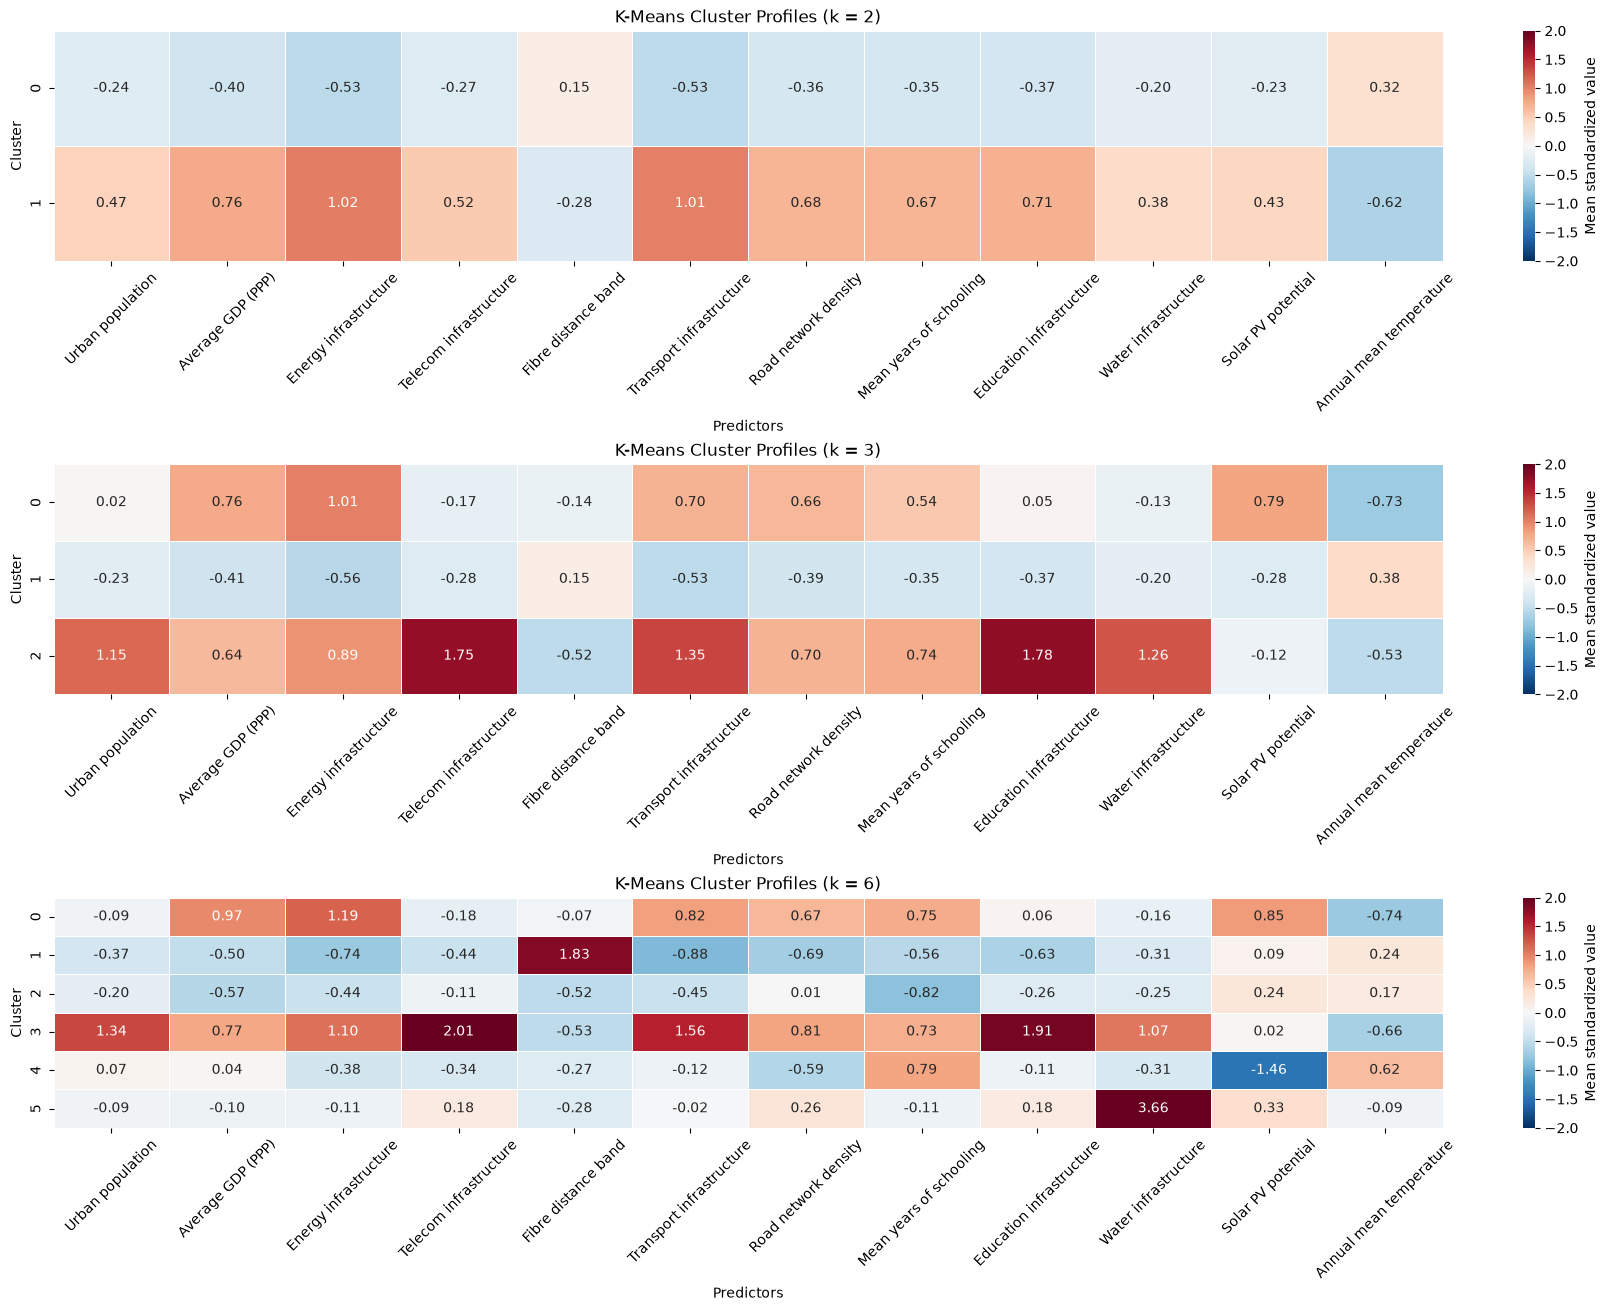

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Descriptive names based on the predictor dictionary
predictor_labels = {
    "GH_POP_TOT_2025": "Urban population",
    "SC_GDP_AVG_2020": "Average GDP (PPP)",
    "IN_CIS_ENE_2020": "Energy infrastructure",
    "IN_CIS_TEL_2020": "Telecom infrastructure",
    "fibre_distance_band_km": "Fibre distance band",
    "IN_CIS_TRA_2020": "Transport infrastructure",
    "IN_ROA_DEN_2024": "Road network density",
    "SC_SEC_SYT_2020": "Mean years of schooling",
    "IN_CIS_EDU_2020": "Education infrastructure",
    "IN_CIS_WAT_2020": "Water infrastructure",
    "CL_REN_PVO_2020": "Solar PV potential",
    "CL_B01_CUR_2010": "Annual mean temperature",
}

# Use existing cluster profiles without refitting models
fig, axes = plt.subplots(
    3, 1, figsize=(16, 13),
    constrained_layout=True
)

for ax, k in zip(axes, [2, 3, 6]):

    profile = cluster_profiles[k].rename(
        columns=predictor_labels
    )

    sns.heatmap(
        profile,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-2,
        vmax=2,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Mean standardized value"}
    )

    ax.set_title(f"K-Means Cluster Profiles (k = {k})")
    ax.set_xlabel("Predictors")
    ax.set_ylabel("Cluster")
    ax.tick_params(axis="x", rotation=45)

plt.show()


## PART 4: Final Model Selection and Justification

**Selected configuration:** K-Means clustering with k = 3, using the 12 predictors following the documented variable-specific transformations and StandardScaler standardization.

The three-cluster solution was selected by considering internal clustering metrics, initialization stability, subsampling stability, cluster sizes and the interpretability of the resulting urban profiles.

Although k = 2 achieved the highest Silhouette score (0.2496) and k = 6 achieved the lowest Davies–Bouldin index (1.6430), k = 3 provided a useful intermediate level of differentiation. Its three clusters contain 522, 1,380 and 270 urban centres, respectively, and exhibit distinct combinations of demographic, socioeconomic, infrastructure and environmental characteristics.

The k = 3 configuration also demonstrated high initialization stability (mean ARI = 0.9939). Subsampling analysis yielded a median ARI of 0.9668, although the lower minimum ARI of 0.4664 indicates sensitivity in some repetitions. Assignment stability was not uniform across clusters, with the smallest cluster showing the greatest average membership changes.

The selected solution is therefore considered suitable for **exploratory urban infrastructure profiling and preliminary investment screening**, rather than definitive classification of AI readiness or investment suitability.

The k = 2 and k = 6 configurations are retained as alternative analytical solutions for comparison and sensitivity assessment.

## PART 5: Final Cluster Assignments and Reproducibility

### Preservation and interpretation of cluster assignments

To support reproducibility and comparative analysis, cluster assignments from all three shortlisted K-Means configurations (k = 2, 3 and 6) will be preserved for each of the 2,172 African urban centres.

The **k = 3 configuration is the selected model** for primary cluster profiling, geographical mapping and preliminary infrastructure investment-screening analysis. The k = 2 and k = 6 configurations are retained for comparison and sensitivity assessment.

**Important methodological note:** Cluster labels are arbitrary identifiers assigned independently within each clustering configuration. Consequently, Cluster 0 under k = 2 does not necessarily correspond to Cluster 0 under k = 3 or k = 6. Numerical labels must not be interpreted as equivalent categories, ordinal rankings or measures of AI readiness.

Meaningful comparisons across configurations require examination of cluster membership overlap and predictor profiles rather than direct comparison of numerical cluster labels.

The final analytical dataset will preserve the urban-centre identifiers, relevant geographic attributes, predictor values and three cluster-assignment columns (`KMeans_k2`, `KMeans_k3` and `KMeans_k6`).

### Identify the available DataFrames

In [11]:

import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")
        print("Columns:", obj.columns.tolist())



df: (2172, 16)
Columns: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distance_band_km', 'IN_CIS_TRA_2020', 'IN_ROA_DEN_2024', 'SC_SEC_SYT_2020', 'IN_CIS_EDU_2020', 'IN_CIS_WAT_2020', 'CL_REN_PVO_2020', 'CL_B01_CUR_2010', 'peeringdb_facility_count']

X_baseline: (2172, 12)
Columns: ['GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distance_band_km', 'IN_CIS_TRA_2020', 'IN_ROA_DEN_2024', 'SC_SEC_SYT_2020', 'IN_CIS_EDU_2020', 'IN_CIS_WAT_2020', 'CL_REN_PVO_2020', 'CL_B01_CUR_2010']

X_prepared: (2172, 12)
Columns: ['GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distance_band_km', 'IN_CIS_TRA_2020', 'IN_ROA_DEN_2024', 'SC_SEC_SYT_2020', 'IN_CIS_EDU_2020', 'IN_CIS_WAT_2020', 'CL_REN_PVO_2020', 'CL_B01_CUR_2010']

X_standard: (2172, 12)
Columns: ['GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distan

### Verify alignment before adding cluster assignments

In [12]:

# Verify alignment between original and standardized datasets
print("Original dataset:", df.shape)
print("Standardized dataset:", X_standard.shape)

print("\nRow indices match:",
      df.index.equals(X_standard.index))

print("\nUrban-centre IDs are unique:",
      df["ID_UC_G0"].is_unique)

print("\nCluster configurations available:",
      sorted(cluster_assignments.keys()))

for k in [2, 3, 6]:
    labels = cluster_assignments[k]
    print(f"k={k}: {len(labels)} assignments")


Original dataset: (2172, 16)
Standardized dataset: (2172, 12)

Row indices match: True

Urban-centre IDs are unique: True

Cluster configurations available: [2, 3, 6]
k=2: 2172 assignments
k=3: 2172 assignments
k=6: 2172 assignments


### Verify predictor values and observation ordering

In [13]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# Verify that all predictor columns have the same order
print("Predictor columns match:",
      X_prepared.columns.equals(X_standard.columns))

# Verify that observation indices match
print("Observation indices match:",
      df.index.equals(X_prepared.index)
      and X_prepared.index.equals(X_standard.index))

# Reconstruct standardized values from prepared predictors
X_check = StandardScaler().fit_transform(X_prepared)

print("Standardized values match:",
      np.allclose(X_check, X_standard.to_numpy(),
                  rtol=1e-5, atol=1e-8))

# Check cluster labels and their expected ranges
for k in [2, 3, 6]:
    labels = np.asarray(cluster_assignments[k])
    print(
        f"k={k}: unique labels = {np.unique(labels)}, "
        f"missing = {pd.isna(labels).sum()}"
    )


Predictor columns match: True
Observation indices match: True
Standardized values match: True
k=2: unique labels = [0 1], missing = 0
k=3: unique labels = [0 1 2], missing = 0
k=6: unique labels = [0 1 2 3 4 5], missing = 0


## Create and export the final dataset

### Final cluster-assignment dataset

In [14]:

from pathlib import Path
import numpy as np
import pandas as pd

# Preserve the original analytical dataset
df_final = df.copy()

# Append cluster assignments from the three configurations
for k in [2, 3, 6]:
    df_final[f"KMeans_k{k}"] = np.asarray(
        cluster_assignments[k], dtype=int
    )

# Validate the final dataset
assert df_final.shape == (2172, 19)
assert df_final["ID_UC_G0"].is_unique
assert df_final[["KMeans_k2", "KMeans_k3", "KMeans_k6"]].notna().all().all()

for k in [2, 3, 6]:
    assert set(df_final[f"KMeans_k{k}"].unique()) == set(range(k))

# Save to the project's processed-data directory
output_path = Path("../data/processed/urban_centres_cluster_assignments.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_final.to_csv(output_path, index=False)

print("Final dataset shape:", df_final.shape)
print("Saved to:", output_path.resolve())

print("\nCluster sizes:")
for k in [2, 3, 6]:
    print(f"\nk = {k}")
    print(df_final[f"KMeans_k{k}"].value_counts().sort_index())

print("\nPreview:")
display(df_final.head())


Final dataset shape: (2172, 19)
Saved to: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed\urban_centres_cluster_assignments.csv

Cluster sizes:

k = 2
KMeans_k2
0    1425
1     747
Name: count, dtype: int64

k = 3
KMeans_k3
0     522
1    1380
2     270
Name: count, dtype: int64

k = 6
KMeans_k6
0    421
1    349
2    714
3    215
4    404
5     69
Name: count, dtype: int64

Preview:


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count,KMeans_k2,KMeans_k3,KMeans_k6
0,38,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0,0,1,2
1,39,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2,1,2,3
2,40,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0,1,2,3
3,41,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0,1,0,0
4,43,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0,0,1,4


### Final dataset summary and interpretation

The final analytical dataset contains **2,172 African urban centres and 19 variables**, comprising the original 16 columns and three additional cluster-assignment columns (`KMeans_k2`, `KMeans_k3` and `KMeans_k6`).

The **K-Means k = 3 configuration** is selected for primary cluster profiling, geographical analysis and preliminary infrastructure investment screening. The k = 2 and k = 6 configurations are retained for comparative analysis and reproducibility.

**Important methodological clarification:** Cluster numbers are arbitrary categorical identifiers assigned by the clustering algorithm. They have **no inherent numerical order, hierarchy or ranking**. For example, Cluster 2 does not represent greater AI readiness, better infrastructure or higher investment suitability than Cluster 1 or Cluster 0. Similarly, cluster numbers are not directly comparable across configurations; Cluster 0 under k = 2 does not necessarily represent the same urban-centre profile as Cluster 0 under k = 3 or k = 6.

Differences between clusters must therefore be interpreted through their underlying demographic, socioeconomic, infrastructure, connectivity and environmental characteristics, rather than their numerical labels.

The resulting clusters represent **exploratory urban infrastructure profiles**, not independently validated AI-readiness categories or investment rankings. Any assessment of relative investment opportunities requires additional contextual evidence and clearly defined investment criteria.